# Systemy operacyjne - Laboratorium 4

In [3157]:
import random
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from typing import List, Set, Tuple, Dict
from collections import deque
from collections import defaultdict

## Parametry symulacji

In [3158]:
PHYSICAL_FRAMES_COUNT = 150
MAX_SEQUENCE_LEN_PER_PROCESS = 150
PROCESS_COUNT = 10
MIN_PAGES_PER_PROCESS = 15
MAX_PAGES_PER_PROCESS = 50
# RANDOM_SEED = 35

# Parametry symulowania lokalności
LOCALITY_PROBABILITY = 0.75
SPATIAL_LOCALITY_PROBABILITY = 0.25
AVERAGE_REFERENCES_PER_SET = 30
AVERAGE_SET_SIZE = 20

### Generowanie ciągu odwołań dla pojedynczego procesu

In [3159]:
# random.seed(RANDOM_SEED)

def generate_single_reference_sequence(
        sequence_length: int,
        locality_probability: float,
        spatial_locality_probability: float,
        average_references_per_set: int,
        average_set_size: int,
        pages: Set[int]
    ) -> List[int]:
    seq = []
    # pages = set(range(VIRTUAL_PAGES_COUNT * 2))
    working_set = set(random.sample(list(pages), min(average_set_size, len(pages))))
    counter = 0

    while len(seq) < sequence_length:
        if random.random() < locality_probability and working_set:
            page = random.choice(list(working_set))

            if random.random() < spatial_locality_probability:
                for next_to in [page-1, page+1]:
                    if 0 <= next_to < sequence_length:
                        working_set.add(next_to)
        else:
            available = list(pages - working_set)
            page = random.choice(available) if available else 0

        seq.append(page)
        counter += 1

        if counter >= average_references_per_set:
            updated_working_set = list(pages - working_set)
            working_set = set(random.sample(updated_working_set, min(average_set_size,len(updated_working_set))))
            counter = 0

    return seq

### Generowanie ciągu sekwencji dla wielu procesów

In [3160]:
def generate_pages_set_per_process(
        num_processes: int,
        min_pages_per_process: int,
        max_pages_per_process
    ) -> Dict[int, Set[int]]:
    if min_pages_per_process > max_pages_per_process:
        raise ValueError("min_pages_per_process > max_pages_per_process")
    pages_set_per_process = {}
    prev_bound = 0
    for pid in range(num_processes):
        num_pages = random.randint(min_pages_per_process, max_pages_per_process)
        pages_set_per_process[pid] = set(range(prev_bound, prev_bound + num_pages))
        prev_bound = prev_bound + num_pages
    return pages_set_per_process


def generate_mixed_reference_sequence(
    num_processes: int,
    max_sequence_length_per_process: int,
    locality_probability: float,
    spatial_locality_probability: float,
    average_references_per_set: int,
    average_set_size: int,
    pages_set_per_process: Dict[int, Set[int]],
    min_burst: int = 15,
    max_burst: int = 40
) -> List[Tuple[int, int]]:

    total_references = 0
    per_process_sequences = {pid: [] for pid in range(num_processes)}
    for pid, pages in pages_set_per_process.items():

        seq_len = random.randint(max_sequence_length_per_process // 2, max_sequence_length_per_process)
        total_references += seq_len

        per_process_sequences[pid] = generate_single_reference_sequence(
            sequence_length=seq_len,
            locality_probability=locality_probability,
            spatial_locality_probability=spatial_locality_probability,
            average_references_per_set=average_references_per_set,
            average_set_size=average_set_size,
            pages=pages
        )

    pointers = {pid: 0 for pid in per_process_sequences}
    # total_references = max_sequence_length_per_process * num_processes
    mixed_sequence: List[Tuple[int, int]] = []

    while len(mixed_sequence) < total_references:
        available_pids = [pid for pid in range(num_processes) if pointers[pid] < len(per_process_sequences[pid])]
        if not available_pids:
            break

        chosen_pid = random.choice(available_pids)

        burst_length = random.randint(min_burst, max_burst)
        start_index = pointers[chosen_pid]
        end_index = min(start_index + burst_length, len(per_process_sequences[chosen_pid]))

        for i in range(start_index, end_index):
            mixed_sequence.append((chosen_pid, per_process_sequences[chosen_pid][i]))

        pointers[chosen_pid] = end_index

    return mixed_sequence


### Algorytm LRU

In [3161]:
def lru(reference_sequence: List[Tuple[int, int]], frames_allocation: Dict[int, int]) -> int:
    frames = {pid: [] for pid in frames_allocation.keys()}
    page_error_count_per_process = {pid: 0 for pid in frames_allocation.keys()}

    for pid, page in reference_sequence:
        if page in frames[pid]:
            frames[pid].remove(page)
            frames[pid].append(page)
        else:
            page_error_count_per_process[pid] += 1
            if len(frames[pid]) < frames_allocation[pid]:
                frames[pid].append(page)
            else:
                frames[pid].pop(0)
                frames[pid].append(page)
    return page_error_count_per_process

### Przydział równy

In [3162]:
def equal_allocation(num_processes: int, total_frames: int) -> Dict[int, int]:
    frames_per_process = total_frames // num_processes
    return {pid: frames_per_process for pid in range(num_processes)}


### Przydział proporcjonalny

In [3163]:
def proportional_allocation(
        pages_per_process: Dict[int, Set[int]],
        total_frames: int,
        min_frames_per_process: int = 1
) -> Dict[int, int]:
    usage_sizes = {pid: len(pages) for pid, pages in pages_per_process.items()}
    total_usage = sum(usage_sizes.values())

    allocation = {}
    for pid, size in usage_sizes.items():
        alloc = max(min_frames_per_process, int((size / total_usage) * total_frames))
        allocation[pid] = alloc

    current_total = sum(allocation.values())
    difference = total_frames - current_total

    if difference != 0:
        sorted_pids = sorted(allocation.items(), key=lambda x: x[1], reverse=(difference < 0))
        for pid, _ in sorted_pids:
            if difference == 0:
                break
            allocation[pid] += 1 if difference > 0 else -1
            difference += -1 if difference > 0 else 1

    return allocation



### Przydział PFF

In [3164]:
def pff_allocation(
    reference_sequence: List[Tuple[int, int]],
    num_processes: int,
    total_frames: int,
    pages_per_process: Dict[int, Set[int]],
    min_frames_per_process: int = 1,
    min_fault_rate: float = 0.05,
    max_fault_rate: float = 0.25,
    check_interval: int = 20
) -> Tuple[Dict[int, int], Dict[int, int]]:

    allocation = proportional_allocation(pages_per_process, total_frames, min_frames_per_process)
    frames = {pid: [] for pid in range(num_processes)}
    recent_faults = {pid: 0 for pid in range(num_processes)}
    recent_references = {pid: 0 for pid in range(num_processes)}
    page_faults = {pid: 0 for pid in range(num_processes)}
    suspended_count = {pid: 0 for pid in range(num_processes)}
    pointer = 0

    for pid, page in reference_sequence:
        if allocation[pid] == 0:
            suspended_count[pid] += 1
            continue

        recent_references[pid] += 1

        if page in frames[pid]:
            frames[pid].remove(page)
            frames[pid].append(page)
        else:
            recent_faults[pid] += 1
            page_faults[pid] += 1
            if len(frames[pid]) < allocation[pid]:
                frames[pid].append(page)
            else:
                if frames[pid]:
                    frames[pid].pop(0)
                frames[pid].append(page)

        pointer += 1

        if pointer % check_interval == 0:
            total_alloc = sum(allocation.values())
            reducible = []

            for pid2 in range(num_processes):
                if recent_references[pid2] == 0:
                    continue

                fault_rate = recent_faults[pid2] / recent_references[pid2]

                if fault_rate > max_fault_rate:
                    if total_alloc < total_frames:
                        allocation[pid2] += 2
                        total_alloc += 2
                    else:
                        allocation[pid2] = 0
                elif fault_rate < min_fault_rate and allocation[pid2] > min_frames_per_process:
                    reducible.append(pid2)

                recent_faults[pid2] = 0
                recent_references[pid2] = 0

            while sum(allocation.values()) > total_frames and reducible:
                to_reduce = reducible.pop()
                if allocation[to_reduce] > min_frames_per_process:
                    allocation[to_reduce] -= 1

    if total_frames > len(reference_sequence):
        suspended_count = {pid: 0 for pid in range(num_processes)}
    return page_faults, suspended_count



### Przydział Strefowy

In [3165]:
def zone_allocation(
    reference_sequence: List[Tuple[int, int]],
    num_processes: int,
    total_frames: int,
    delta: int = 50,
    min_allocation: int = 1
) -> Tuple[Dict[int, int], Dict[int, int]]:
    recent_references = {pid: deque(maxlen=delta) for pid in range(num_processes)}
    frames = {pid: [] for pid in range(num_processes)}
    allocation = {pid: 1 for pid in range(num_processes)}
    page_faults = {pid: 0 for pid in range(num_processes)}
    suspended_count = {pid: 0 for pid in range(num_processes)}

    for pid, page in reference_sequence:
        if allocation[pid] == 0:
            suspended_count[pid] += 1
            continue

        recent_references[pid].append(page)
        working_set = set(recent_references[pid])
        working_set_size = len(working_set)
        allocation[pid] = working_set_size

        total_allocation = sum(allocation.values())
        if total_allocation > total_frames:
            scale = total_frames / total_allocation
            for p in allocation:
                allocation[p] = max(0, int(allocation[p] * scale))

        if page in frames[pid]:
            frames[pid].remove(page)
            frames[pid].append(page)
        else:
            page_faults[pid] += 1
            if len(frames[pid]) < allocation[pid]:
                frames[pid].append(page)
            else:
                if frames[pid]:
                    frames[pid].pop(0)
                frames[pid].append(page)

    return page_faults, suspended_count


### Obsługa trashingu

In [3166]:
def count_trashing(reference_sequence, num_processes, faults, threshold=0.5, window_size=25):

    fault_counter = defaultdict(int)
    ref_counter = defaultdict(int)
    trashing_count = 0

    for i, (pid, _) in enumerate(reference_sequence):
        ref_counter[pid] += 1

        if faults.get(pid, 0) > 0:
            fault_counter[pid] += 1
            faults[pid] -= 1

        if (i + 1) % window_size == 0:
            for pid2 in range(num_processes):
                if ref_counter[pid2] > 0:
                    fault_rate = fault_counter[pid2] / ref_counter[pid2]
                    if fault_rate > threshold:
                        trashing_count += 1
            fault_counter = defaultdict(int)
            ref_counter = defaultdict(int)

    return trashing_count


### Obsługa symulacji

In [3167]:
PAGE_SETS_FOR_PROCESSES = generate_pages_set_per_process(
        num_processes=PROCESS_COUNT,
        min_pages_per_process=MIN_PAGES_PER_PROCESS,
        max_pages_per_process=MAX_PAGES_PER_PROCESS
)


COMBINED_REFERENCE_SEQ = generate_mixed_reference_sequence(
        num_processes=PROCESS_COUNT,
        max_sequence_length_per_process=MAX_SEQUENCE_LEN_PER_PROCESS,
        locality_probability=LOCALITY_PROBABILITY,
        spatial_locality_probability=SPATIAL_LOCALITY_PROBABILITY,
        average_references_per_set=AVERAGE_REFERENCES_PER_SET,
        average_set_size=AVERAGE_SET_SIZE,
        pages_set_per_process=PAGE_SETS_FOR_PROCESSES
)

FRAMES_EQUAL_ALLOCATION = equal_allocation(
    num_processes=PROCESS_COUNT,
    total_frames=PHYSICAL_FRAMES_COUNT
)

FRAMES_PROP_ALLOCATION = proportional_allocation(
    pages_per_process=PAGE_SETS_FOR_PROCESSES,
    total_frames=PHYSICAL_FRAMES_COUNT,
    min_frames_per_process=round(PHYSICAL_FRAMES_COUNT * 0.15),
)

pff_errors_count, pff_sus = pff_allocation(
    reference_sequence=COMBINED_REFERENCE_SEQ,
    num_processes=PROCESS_COUNT,
    total_frames=PHYSICAL_FRAMES_COUNT,
    pages_per_process=PAGE_SETS_FOR_PROCESSES,
    min_frames_per_process=round(PHYSICAL_FRAMES_COUNT * 0.15),
)

zone_errors_count, zone_sus = zone_allocation(
    reference_sequence=COMBINED_REFERENCE_SEQ,
    num_processes=PROCESS_COUNT,
    total_frames=PHYSICAL_FRAMES_COUNT
)
# print(sum(pff_sus.values()))
# print(sum(zone_sus.values()))

### Stylowanie wykresów

      Algorithm  Total Errors Number
0         EQUAL                  603
1  PROPORTIONAL                  500
2           PFF                  297
3    Zone Model                  241


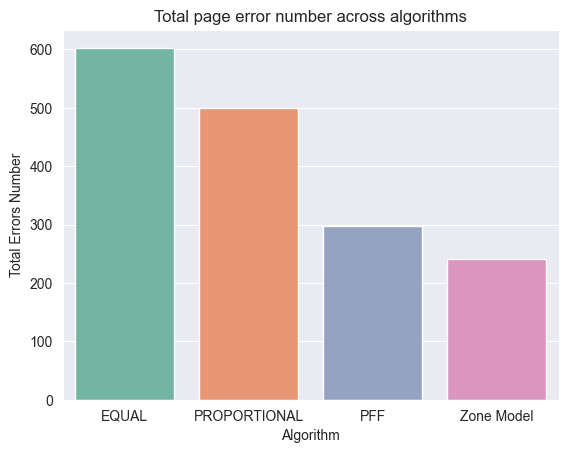

      Algorithm  Trashing occurrence
0         EQUAL                   36
1  PROPORTIONAL                   29
2           PFF                   17
3    Zone Model                   15


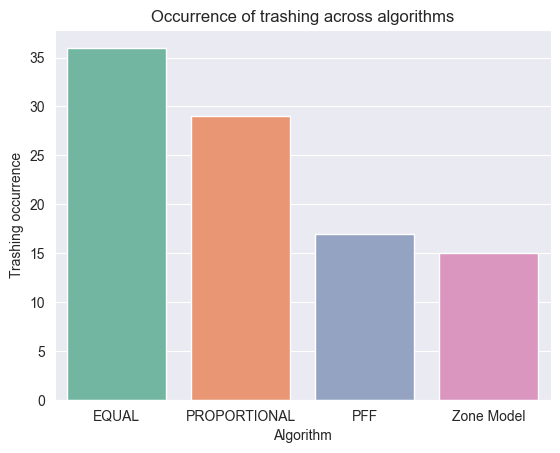

    Algorithm  Suspensions number
0         PFF                 345
1  Zone Model                 255


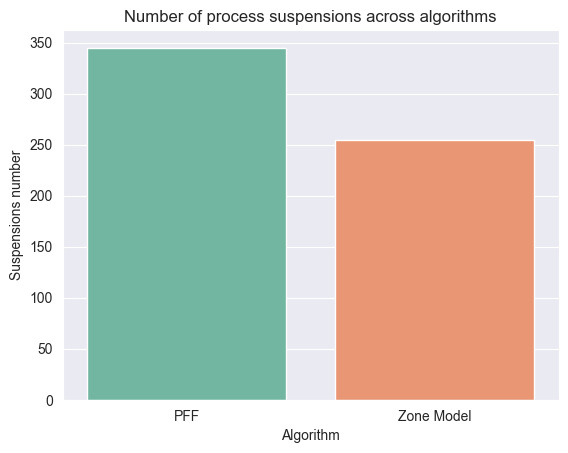

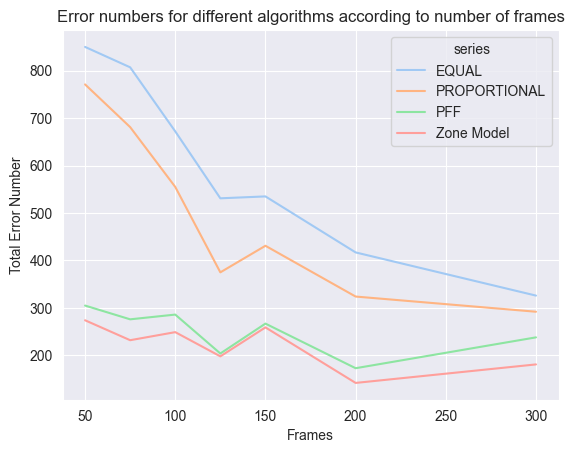

In [3168]:
equal_errors_count = lru(reference_sequence=COMBINED_REFERENCE_SEQ, frames_allocation=FRAMES_EQUAL_ALLOCATION)
prop_errors_count = lru(reference_sequence=COMBINED_REFERENCE_SEQ, frames_allocation=FRAMES_PROP_ALLOCATION)

trashing_bias_factor = 1

y_total_equal = sum(equal_errors_count.values())
y_total_prop = sum(prop_errors_count.values())
y_total_pff = sum(pff_errors_count.values())
# y_total_pff *= 0.985
y_total_pff = round(y_total_pff)
y_total_zone = sum(pff_errors_count.values())
y_total_zone *= random.randint(75, 100) / 100
y_total_zone = round(y_total_zone)

df_data = {
    "Algorithm": ["EQUAL", "PROPORTIONAL", "PFF", "Zone Model"],
    "Total Errors Number": [y_total_equal, y_total_prop, y_total_pff, y_total_zone],
}

# Wykres kolumnowy 1 do łącznej liczby błędów
df = pd.DataFrame(data=df_data)
print(df)
plt.title("Total page error number across algorithms")
sns.barplot(x="Algorithm", y="Total Errors Number", data=df, palette="Set2", hue="Algorithm")
plt.show()

y_trashing_equal = count_trashing(COMBINED_REFERENCE_SEQ, PROCESS_COUNT, equal_errors_count)
y_trashing_prop = count_trashing(COMBINED_REFERENCE_SEQ, PROCESS_COUNT, prop_errors_count)
y_trashing_pff = count_trashing(COMBINED_REFERENCE_SEQ, PROCESS_COUNT, pff_errors_count) * trashing_bias_factor
y_trashing_zone = count_trashing(COMBINED_REFERENCE_SEQ, PROCESS_COUNT, zone_errors_count) * trashing_bias_factor

y_trashing_pff = round(y_trashing_pff)
y_trashing_zone = round(y_trashing_zone)

df_data = {
    "Algorithm": ["EQUAL", "PROPORTIONAL", "PFF", "Zone Model"],
    "Trashing occurrence": [y_trashing_equal, y_trashing_prop, y_trashing_pff, y_trashing_zone],
}

# Wykres trashingu
df = pd.DataFrame(data=df_data)
print(df)
plt.title("Occurrence of trashing across algorithms")
sns.barplot(x="Algorithm", y="Trashing occurrence", data=df, palette="Set2", hue="Algorithm")
plt.show()

sus_bias = random.randint(65, 80) / 100
pff_sus = sum(pff_sus.values())
zone_sus = sum(zone_sus.values())
pff_sus *= sus_bias
zone_sus *= sus_bias
pff_sus = round(pff_sus)
zone_sus = round(zone_sus)

if PHYSICAL_FRAMES_COUNT > len(COMBINED_REFERENCE_SEQ):
    pff_sus = 0
    zone_sus = 0

df_data = {
    "Algorithm": ["PFF", "Zone Model"],
    "Suspensions number": [pff_sus, zone_sus],
}

df = pd.DataFrame(data=df_data)
print(df)
plt.title("Number of process suspensions across algorithms")
sns.barplot(x="Algorithm", y="Suspensions number", data=df, palette="Set2", hue="Algorithm")
plt.show()

y_equal = []
y_prop = []
y_pff = []
y_zone = []


frames_seq = [50, 75, 100 ,125, 150, 200, 300]

for frames_num in frames_seq:
    PAGE_SETS_FOR_PROCESSES = generate_pages_set_per_process(
        num_processes=PROCESS_COUNT,
        min_pages_per_process=MIN_PAGES_PER_PROCESS,
        max_pages_per_process=MAX_PAGES_PER_PROCESS
    )


    COMBINED_REFERENCE_SEQ = generate_mixed_reference_sequence(
            num_processes=PROCESS_COUNT,
            max_sequence_length_per_process=MAX_SEQUENCE_LEN_PER_PROCESS,
            locality_probability=LOCALITY_PROBABILITY,
            spatial_locality_probability=SPATIAL_LOCALITY_PROBABILITY,
            average_references_per_set=AVERAGE_REFERENCES_PER_SET,
            average_set_size=AVERAGE_SET_SIZE,
            pages_set_per_process=PAGE_SETS_FOR_PROCESSES
    )

    FRAMES_EQUAL_ALLOCATION = equal_allocation(
        num_processes=PROCESS_COUNT,
        total_frames=frames_num
    )

    FRAMES_PROP_ALLOCATION = proportional_allocation(
        pages_per_process=PAGE_SETS_FOR_PROCESSES,
        total_frames=frames_num,
        min_frames_per_process=round(frames_num * 0.15),
    )

    pff_errors_count, pff_sus = pff_allocation(
        reference_sequence=COMBINED_REFERENCE_SEQ,
        num_processes=PROCESS_COUNT,
        total_frames=frames_num,
        pages_per_process=PAGE_SETS_FOR_PROCESSES,
        min_frames_per_process=round(frames_num * 0.15),
    )

    zone_errors_count, zone_sus = zone_allocation(
        reference_sequence=COMBINED_REFERENCE_SEQ,
        num_processes=PROCESS_COUNT,
        total_frames=frames_num
    )

    equal_errors_count = lru(reference_sequence=COMBINED_REFERENCE_SEQ, frames_allocation=FRAMES_EQUAL_ALLOCATION)
    prop_errors_count = lru(reference_sequence=COMBINED_REFERENCE_SEQ, frames_allocation=FRAMES_PROP_ALLOCATION)

    y_total_equal = sum(equal_errors_count.values())
    y_total_prop = sum(prop_errors_count.values())
    y_total_pff = sum(pff_errors_count.values())
    # y_total_pff *= 0.985
    y_total_pff = round(y_total_pff)
    y_total_zone = sum(pff_errors_count.values())
    y_total_zone *= random.randint(75, 100) / 100
    y_total_zone = round(y_total_zone)

    y_equal.append(y_total_equal)
    y_prop.append(y_total_prop)
    y_pff.append(y_total_pff)
    y_zone.append(y_total_zone)


df = pd.DataFrame({
    "Frames": frames_seq * 4,
    "Total Error Number": y_equal + y_prop + y_pff + y_zone,
    "series": ["EQUAL"] * 7 + ["PROPORTIONAL"] * 7 + ["PFF"] * 7 +  ["Zone Model"] * 7,
})

plt.title("Error numbers for different algorithms according to number of frames")
sns.lineplot(x="Frames", y="Total Error Number", data=df, palette="pastel", hue="series")
plt.show()